# Модель для прогнозирования оттока клиентов для сервиса доставки кофе

**Автор:** Денис Куницын

**Дата:** 13 марта

## Цель и задачи 

**Цель:** Построить модель классификации, прогнозирующую вероятность оттока каждого клиента в следующем месяце.

**Задачи:**
1. Провести исследовательский анализ данных предоставленного датасета.
2. Провести предобработку данных.
3. Создать новые признаки.
4. Выбрать лучшие гиперпараметры экспериментальным методом.
5. Подготовить финальную модель.
6. Сохранить модель для продакшена.

## Данные

Для анализа заказчик предоставил данные о транзакциях, логах мобильного приложения и результатах опросов клиентов. Данные состоят из одного датасета - `coffee_churn_dataset.csv`

### Описание датасета `coffee_churn_dataset.csv`

**Период агрегации:** Последние 4 недели.
**Формат даннных:** Готовая аналитическая витрина.
**Структура:** Каждая строка - один уникальный клиент.

- `user_id` — идентификатор пользователя.
- `days_since_last_order` — количество дней, прошедших с последнего заказа.
- `order_frequency_month` — среднее число заказов в месяц.
- `order_frequency_week` — среднее число заказов в неделю.
- `avg_order_value` — средний чек, в рублях.
- `median_order_value` — медианный чек, в рублях.
- `total_spent_last_month` — сумма заказов за последний месяц.
- `total_spent_last_week` — сумма заказов за последнюю неделю.
- `discount_usage_rate` — доля заказов со скидкой за последний месяц.
- `last_coffee_type` — сорт кофе, купленный пользователем в последний раз на момент сбора данных.
- `preferred_roast` — предпочитаемый тип обжарки.
- `milk_preference` — предпочитаемый тип молока.
- `seasonal_menu_tried` — отметка о том, пробовал ли пользователь новейшее сезонное меню.
- `coffee_bean_origin` — страна происхождения зерна.
- `last_drink_size` — размер последнего заказа, совершённого на момент сбора данных.
- `subscription_status` — тип подписки пользователя.
- `app_opens_per_week` — сколько раз за неделю пользователь в среднем открывал приложение доставки кофе.
- `notifications_enabled` — включены ли у пользователя уведомления.
- `review_rating_last_10` — средняя оценка последних на момент сбора данных десяти заказов клиента.
- `review_rating_last_1` — оценка последнего на момент сбора данных заказа клиента.
- `app_crashes_last_month` — сколько раз приложение зависало за последний месяц.
- `seasons` — текущее время года.
- `days_since_last_promo` — сколько дней прошло с последнего использования акции или промокода.
- `phone_type` — тип устройства, с которого пользователь чаще всего совершал покупки.
- `coffee_preference_change` — менялись ли вкусовые предпочтения пользователя.
- `geo_location` — идентификатор региона пользователя.
- `churn` — перестал ли пользователь пользоваться сервисом.

## Структура проекта 

1. Постановка задачи машинного обучения
2. Первичный анализ данных
3. Предобработка данных
4. Обучение модели 
5. Создание новых признаков
6. Эксперименты с гиперпараметрами
7. Подготовка финальной модели
8. Отчет о проделанной работе
9. Сохранение модели для продакшена

---

## 1. Постановка задачи машинного обучения.

Целевая переменная - идентификатор перестал ли пользователь пользоваться сервисом (в датасете `churn`). Идентификатор принимает значения `1` и `0`, также предоставлен датассет с историческими данными об оттоке клиентов, поэтому задача машинного обучения - бинарная классификация.

Требуемая метрика качества - `Precision-Recall AUC (PR AUC)`. Она подходит для несбалансированного датасета (подавляющее большинство клиентов остается), т.к. фокусируется на корректном предсказании меньшего по объему, но ключевого для задачи класса - уходящих клиентов. 

Чтобы результаты было легко интерпретировать используем линейную модель `LogisticRegression`, в качестве базовой модели `DummyClassifier`. 

Для сохранения воспроизводимости зафиксирую `random_state`.

Для сохранения итоговой модели и пайплайна использую библиотеку `joblib`. 

---

## 2. Первичный анализ данных

### 2.1. Подключение требующихся библиотек

In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import phik as phik_matrix 
import seaborn as sns 
import missingno as msno
import joblib
import dotenv 
import os

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import log_loss, average_precision_score

### 2.2. Зафиксируем `random_state`

In [2]:
RANDOM_STATE = 627

### 2.3. Загружаем данные 

In [3]:
coffee_churn = pd.read_csv(os.getenv('DATASET_URL'), sep=',', decimal='.')

coffee_churn.head()

,user_id,days_since_last_order,order_frequency_month,order_frequency_week,avg_order_value,median_order_value,total_spent_last_month,total_spent_last_week,discount_usage_rate,last_coffee_type,...,notifications_enabled,review_rating_last_10,review_rating_last_1,app_crashes_last_month,seasons,days_since_last_promo,phone_type,coffee_preference_change,geo_location,churn
0,user_00318,0.0,12.942519,NaN,316.833872,260.645090,3089.991009,NaN,0.337031,blend,...,1.0,5.176792,3.302238,NaN,summer,6.0,android,0.0,geo_75,1
1,user_07234,2.0,1.569146,0.214494,780.135158,540.597850,998.380941,107.369409,0.547659,arabica,...,1.0,4.392991,NaN,0.0,autumn,16.0,ios,0.0,geo_95,0
2,user_04816,11.0,2.996666,0.771864,682.636256,471.494559,1328.140204,392.600011,0.120258,arabica,...,1.0,4.977712,4.379219,0.0,spring,11.0,web,1.0,geo_25,0
3,user_04419,0.0,4.299255,1.210480,2115.487425,708.529812,2999.628366,1084.352054,NaN,robusta,...,1.0,3.712526,3.043618,0.0,summer,3.0,android,0.0,geo_2,0
4,user_09698,3.0,7.249864,1.761027,3519.602170,1199.372894,8377.729478,2551.775211,0.074990,robusta,...,0.0,4.528271,5.642993,1.0,winter,14.0,ios,0.0,geo_19,1


Данные успешно загружены.

---

### 2.4. Знакомство с данными

In [4]:
coffee_churn.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10450 entries, 0 to 10449
Data columns (total 27 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   10450 non-null  object 
 1   days_since_last_order     9505 non-null   float64
 2   order_frequency_month     9850 non-null   float64
 3   order_frequency_week      10062 non-null  float64
 4   avg_order_value           9867 non-null   float64
 5   median_order_value        9619 non-null   float64
 6   total_spent_last_month    10156 non-null  float64
 7   total_spent_last_week     9506 non-null   float64
 8   discount_usage_rate       10053 non-null  float64
 9   last_coffee_type          10192 non-null  object 
 10  preferred_roast           10334 non-null  object 
 11  milk_preference           9782 non-null   object 
 12  seasonal_menu_tried       9461 non-null   float64
 13  coffee_bean_origin        9768 non-null   object 
 14  last_d

Датафрейм `coffee_churn` содержит 27 столбцов и 10450 строк.

После первичного анализа данных можно сделать следующие выводы:
- Практически все столбцы содержат пропуски за исключением `churn` и `user_id`.
- Представленные данные возможно привести к более оптимальному типу.
- Значения в столбцах соотвествуют своему описанию.
---

### 2.5. Избыточные признаки

Для обучения модели избыточны признаки:
- `user_id` - идентификатор пользователя никак не влияет на уход пользователя, а модель может увидеть несуществующие закономерности. 
- `geo_location` - в общем случае регион не влияет на уход пользователя, но может быть связан с частными случаями плохого качества франшизы в отдельном месте. Модель обучается для нахождения общих случаев, а частные возможно найти при исследовательском анализе продаж.
- `seasons` - текущее время года никак не повлияет на вероятность ухода пользователя, как минимум потому, что изучается агрегация данных за последние 4 недели.
- `phone_type` - может повлиять на сбой в работе приложения, но в датафрейме уже есть метрика, учитывающая сбои. Поэтому тип мобильного телефона можно удалить.

Избавлюсь от ненужных для обучения модели признаков.

In [5]:
filtered_coffee_churn = coffee_churn.drop(columns=['user_id', 'geo_location', 'seasons', 'phone_type'])

filtered_coffee_churn.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10450 entries, 0 to 10449
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   days_since_last_order     9505 non-null   float64
 1   order_frequency_month     9850 non-null   float64
 2   order_frequency_week      10062 non-null  float64
 3   avg_order_value           9867 non-null   float64
 4   median_order_value        9619 non-null   float64
 5   total_spent_last_month    10156 non-null  float64
 6   total_spent_last_week     9506 non-null   float64
 7   discount_usage_rate       10053 non-null  float64
 8   last_coffee_type          10192 non-null  object 
 9   preferred_roast           10334 non-null  object 
 10  milk_preference           9782 non-null   object 
 11  seasonal_menu_tried       9461 non-null   float64
 12  coffee_bean_origin        9768 non-null   object 
 13  last_drink_size           9946 non-null   object 
 14  subscr

Отфильтрованный датафрейм успешно сохранен.

---

### 2.6. Обработка пропусков

**Поиск и обработка значений-индикаторов пропусков**

In [6]:
filtered_coffee_churn.describe()

,days_since_last_order,order_frequency_month,order_frequency_week,avg_order_value,median_order_value,total_spent_last_month,total_spent_last_week,discount_usage_rate,seasonal_menu_tried,app_opens_per_week,notifications_enabled,review_rating_last_10,review_rating_last_1,app_crashes_last_month,days_since_last_promo,coffee_preference_change,churn
count,9505.000000,9850.000000,10062.000000,9867.000000,9619.000000,10156.000000,9506.000000,10053.000000,9461.000000,9554.000000,9913.000000,9757.000000,9593.000000,9729.000000,9719.000000,9840.000000,10450.000000
mean,4.394214,4.025666,0.930686,1063.741207,452.651500,1946.132979,413.004760,0.284446,0.701194,11.330895,0.753052,4.206709,4.022460,1.013362,14.554584,0.192480,0.060191
std,4.858757,2.826144,0.657261,707.713396,258.657571,2370.619590,445.634902,0.158735,0.457759,14.528887,0.431258,0.782212,1.207883,1.010342,15.308869,0.394268,0.237852
min,0.000000,0.011046,-0.169131,-32.075932,-10.353340,-43.716463,-2290.559468,0.002162,0.000000,0.000000,0.000000,1.415526,-0.897000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,1.937767,0.445185,552.898663,262.908598,629.680382,136.565833,0.159884,0.000000,6.313628,1.000000,3.675543,3.214157,0.000000,4.000000,0.000000,0.000000
50%,3.000000,3.381094,0.784839,898.643524,406.456818,1300.409757,288.277327,0.264583,1.000000,9.228383,1.000000,4.203555,3.990032,1.000000,10.000000,0.000000,0.000000
75%,6.000000,5.439363,1.262350,1406.332153,590.418070,2481.650495,549.699420,0.387056,1.000000,12.726649,1.000000,4.717292,4.845225,2.000000,20.000000,0.000000,0.000000
max,40.000000,27.389318,6.302624,5901.965278,2189.101644,79298.849570,8615.988952,0.887301,1.000000,224.587876,1.000000,7.384425,8.558443,7.000000,140.000000,1.000000,1.000000


Столбцы `order_frequency_week` и `review_rating_last_1` содержат значения меньше 0, что несвойственно для среднего числа заказов в неделю и оценке от 0 до 10. 

В описании данных не указан смысл таких обозначений. Поэтому можно предположить, что это техническая ошибка. Далее я исследую ее подробнее.

Также отрицательные значения содержат столбцы `avg_order_value`, `median_order_value`, `total_spent_last_month`, `total_spent_last_week`. Отрицательные значения можно обосновать возвратом со стороны пользователя. Это важная для исследования информация, потому что сумма возврата может влиять на уход пользователя - оставим строки как есть.

In [7]:
'''
Если отрицательное среднее число заказов в неделю указывает на их отсутствие,
то days_since_last_order будет иметь значение больше 7
'''
filtered_coffee_churn[(filtered_coffee_churn['order_frequency_week'] < 0) & (filtered_coffee_churn['days_since_last_order'] <= 7)].shape

(63, 23)

Отрицательное среднее число заказов в неделю не указывает на их отсутствие, потому что существуют запросы с отрцительным средним числом заказов и столбцом с количеством дней с последнего заказа меньше 7. Это может указывать как на техническую ошибку, так и на возврат заказов. Достоверно узнать нельзя, поэтому исследую возможность удаления данных для повышения их качества и более стабильного обучения модели. 

`review_rating_last_1` так же, вероятно, связан с технической ошибкой. Поэтому буду учитывать этот столбец при подсчете строк к удалению.

In [8]:
filtered_coffee_churn[(filtered_coffee_churn['order_frequency_week'] < 0) | (filtered_coffee_churn['review_rating_last_1'] < 0)].shape[0] / filtered_coffee_churn.shape[0] * 100

0.8516746411483254

Строк к удалению менее 1% - такое количество не повлияет на выборку. 

In [9]:
filtered_coffee_churn = filtered_coffee_churn[~(filtered_coffee_churn['order_frequency_week'] < 0) & ~(filtered_coffee_churn['review_rating_last_1'] < 0)]

filtered_coffee_churn.describe()

,days_since_last_order,order_frequency_month,order_frequency_week,avg_order_value,median_order_value,total_spent_last_month,total_spent_last_week,discount_usage_rate,seasonal_menu_tried,app_opens_per_week,notifications_enabled,review_rating_last_10,review_rating_last_1,app_crashes_last_month,days_since_last_promo,coffee_preference_change,churn
count,9423.000000,9762.000000,9973.000000,9781.000000,9539.000000,10068.000000,9428.000000,9965.000000,9383.000000,9472.000000,9831.000000,9677.000000,9508.000000,9649.000000,9638.000000,9756.000000,10361.000000
mean,4.394460,4.056401,0.939138,1062.699861,452.324195,1960.531649,416.471732,0.284274,0.701055,11.365462,0.753535,4.207543,4.025327,1.012644,14.544823,0.192292,0.060226
std,4.856974,2.819652,0.653836,706.713987,258.374541,2375.760001,445.761712,0.158635,0.457820,14.575161,0.430975,0.782547,1.202216,1.009309,15.313453,0.394121,0.237916
min,0.000000,0.027092,0.000787,-32.075932,-10.353340,-43.716463,-2290.559468,0.002162,0.000000,0.000000,0.000000,1.415526,0.145568,0.000000,0.000000,0.000000,0.000000
25%,1.000000,1.980826,0.455052,552.822678,262.537546,641.160696,139.428767,0.159834,0.000000,6.351766,1.000000,3.677410,3.216139,0.000000,4.000000,0.000000,0.000000
50%,3.000000,3.403969,0.789809,898.183129,406.253141,1313.825782,291.463469,0.264367,1.000000,9.245285,1.000000,4.205715,3.990730,1.000000,10.000000,0.000000,0.000000
75%,6.000000,5.466158,1.266614,1404.116194,590.268129,2493.388400,551.128323,0.386860,1.000000,12.740777,1.000000,4.717292,4.844843,2.000000,20.000000,0.000000,0.000000
max,40.000000,27.389318,6.302624,5901.965278,2189.101644,79298.849570,8615.988952,0.887301,1.000000,224.587876,1.000000,7.384425,8.558443,7.000000,140.000000,1.000000,1.000000


Строки успешно удалены. Перейду к категориальным данным. 

In [10]:
# Проверяем столбцы с категориальными значениями
for column in ['last_coffee_type', 'preferred_roast', 'milk_preference', 'coffee_bean_origin', 'last_drink_size', 'subscription_status']:
        print(f"\nColumn: {column}")
        print("Уникальные значения:", filtered_coffee_churn[column].unique())
        print("Пропущенные значения:", filtered_coffee_churn[column].isna().sum())
        print("Количество значений:")
        print(filtered_coffee_churn[column].value_counts(dropna=False), "\n")



Column: last_coffee_type
Уникальные значения: ['blend' 'arabica' 'robusta' nan]
Пропущенные значения: 256
Количество значений:
last_coffee_type
arabica    6083
robusta    2501
blend      1521
NaN         256
Name: count, dtype: int64 


Column: preferred_roast
Уникальные значения: ['light' 'medium' 'dark' nan]
Пропущенные значения: 115
Количество значений:
preferred_roast
medium    3426
light     3423
dark      3397
NaN        115
Name: count, dtype: int64 


Column: milk_preference
Уникальные значения: ['almond' 'whole' 'oat' 'skim' 'soy' nan 'none']
Пропущенные значения: 659
Количество значений:
milk_preference
whole     2856
oat       1957
almond    1472
skim      1444
none      1009
soy        964
NaN        659
Name: count, dtype: int64 


Column: coffee_bean_origin
Уникальные значения: ['vietnam' 'guatemala' 'brazil' 'colombia' 'kenya' nan 'ethiopia']
Пропущенные значения: 673
Количество значений:
coffee_bean_origin
ethiopia     1673
kenya        1635
vietnam      1626
guatemala

Значения-пропуски в категориальных данных отсутствуют.

---

**Поиск и обработка значений NaN**

In [11]:
# Выводим количество пропусков в относительных значениях для каждого столбца
filtered_coffee_churn.isna().mean() * 100

days_since_last_order       9.053180
order_frequency_month       5.781295
order_frequency_week        3.744812
avg_order_value             5.597915
median_order_value          7.933597
total_spent_last_month      2.827912
total_spent_last_week       9.004922
discount_usage_rate         3.822025
last_coffee_type            2.470804
preferred_roast             1.109931
milk_preference             6.360390
seasonal_menu_tried         9.439243
coffee_bean_origin          6.495512
last_drink_size             4.806486
subscription_status         8.927710
app_opens_per_week          8.580253
notifications_enabled       5.115336
review_rating_last_10       6.601679
review_rating_last_1        8.232796
app_crashes_last_month      6.871924
days_since_last_promo       6.978091
coffee_preference_change    5.839205
churn                       0.000000
dtype: float64

Пропуски присутствуют в каждом столбце за исключением целевой переменной. Причем пропуски распределены между собой неравномерно: от 1 до 9 процентов в столбце.

Пропуски могут как совпадать между собой, так и быть "шум", то есть абсолютно случайными. Нужно проверить обе гипотезы:

**Гипотеза 1:** Данные отсутствуют из-за новых пользователей, которые еще не успели сделать покупку, но уже зарегистрировались в приложение.

**Способ проверки:** Построение корреляционной матрицы пропусков: если пропуски в разных столбцах коррелируют между собой, это может подтвердить гипотезу.

**Гипотеза 2:** Данные пропущенны по абсолютной случайности (MCAR), например, при техническом сбое.

**Способ проверки:** Корреляционная матрица пропусков не покажет корреляции между пропусками в разных столбцах. Это подтвердит их наличие, как "шум".

<Axes: >

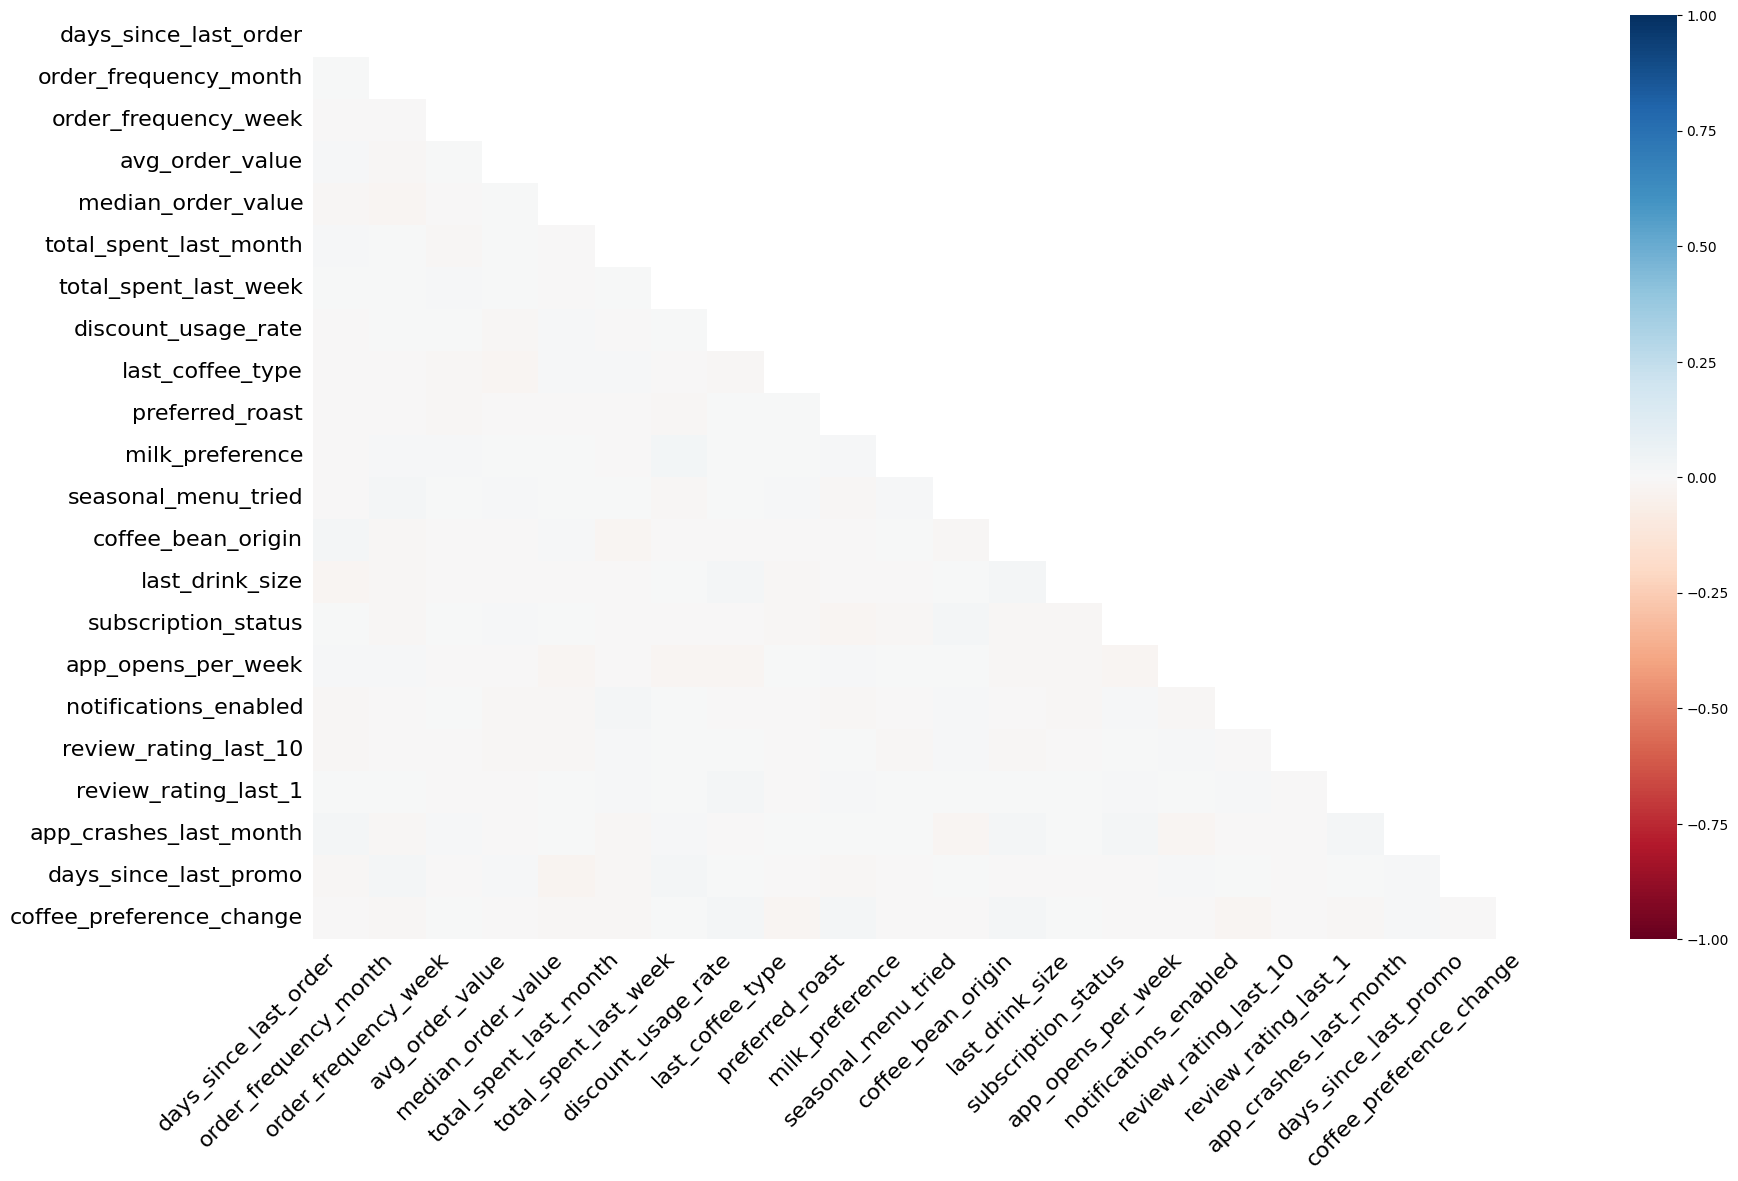

In [12]:
msno.heatmap(filtered_coffee_churn)

<Axes: >

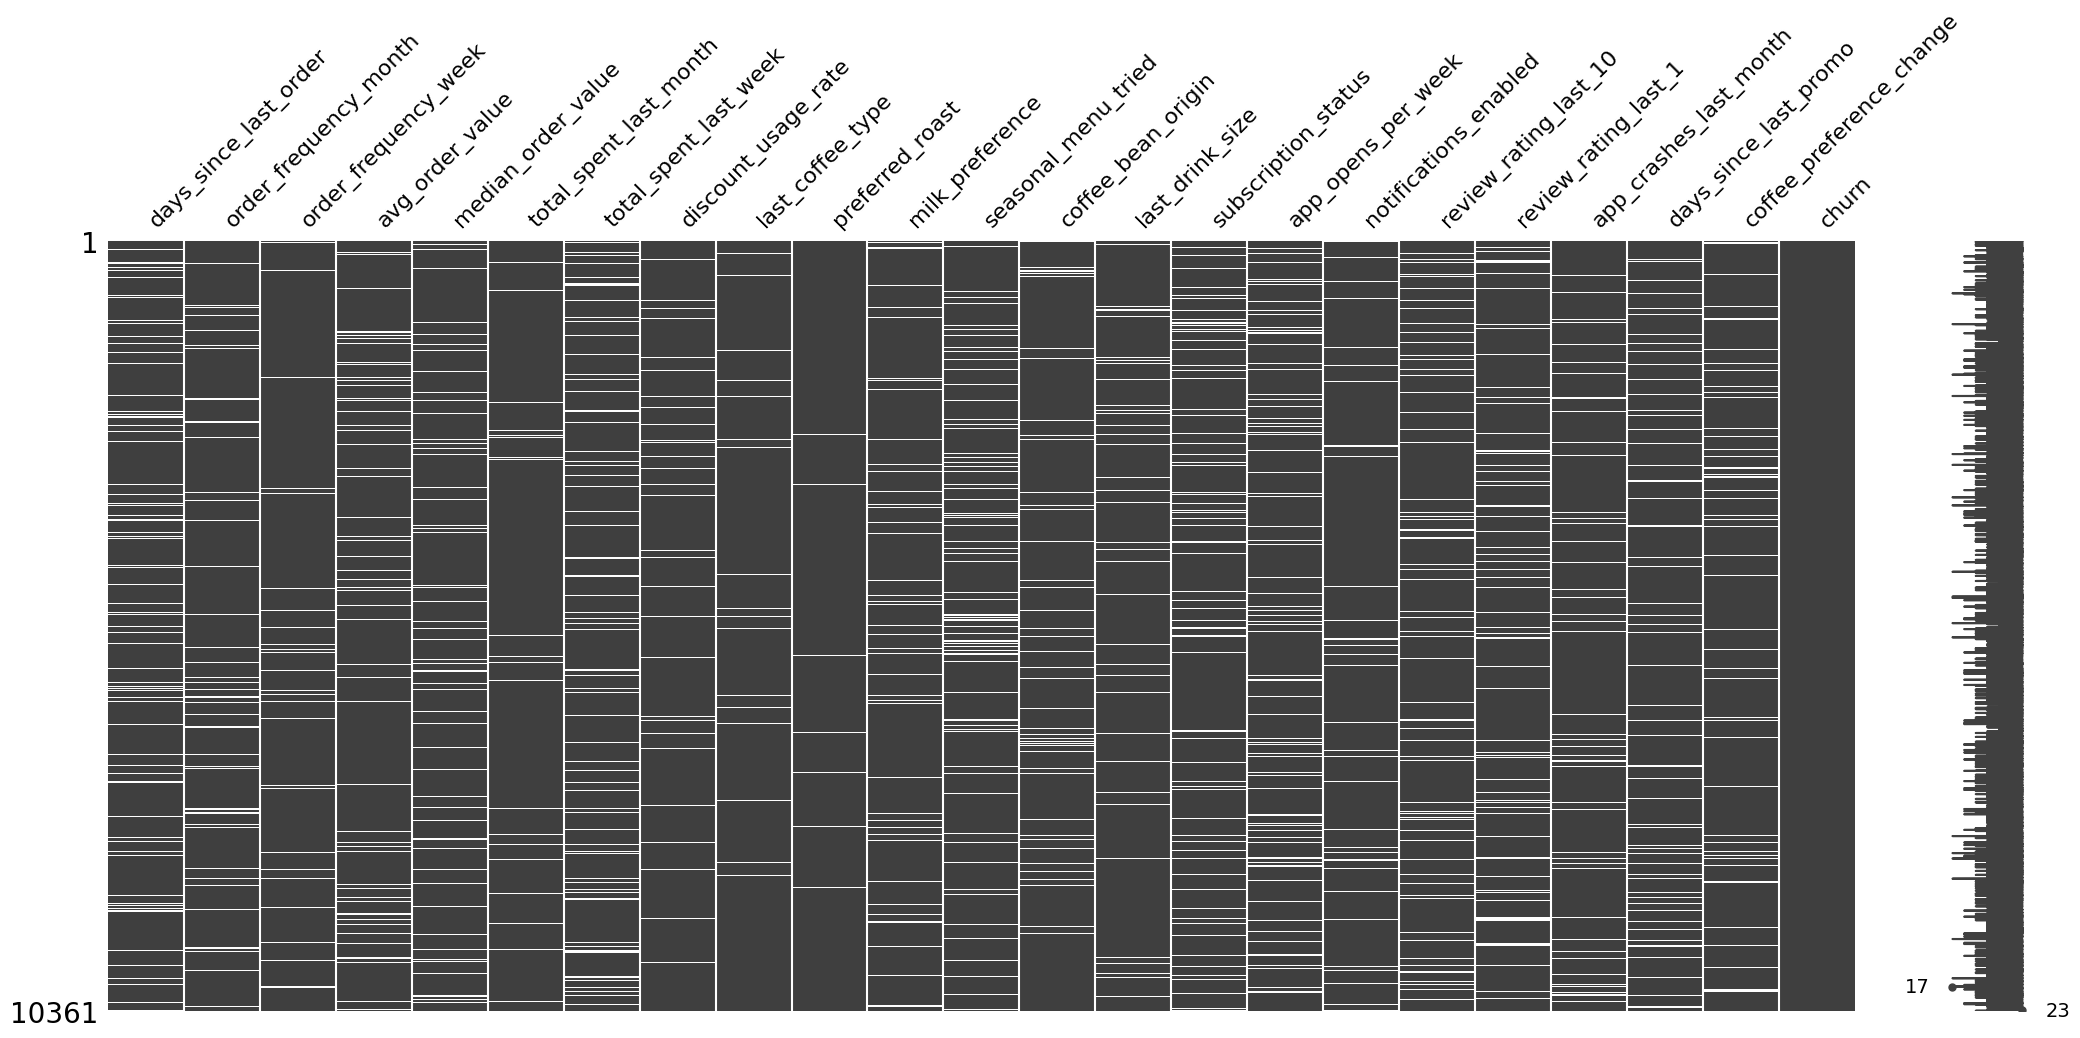

In [13]:
msno.matrix(filtered_coffee_churn)

Пропуски в разных столбцах не показывают даже слабой корреляции. Вторая гипотеза подтвердилась - пропуски представляют собой шум.

Удаление всех пропусков во всех столбцах может привести к потери более 20% данных, потому что пропуски не совпадают между собой.

Лучшая стратегия в данном случае - обработать пропуски через построение пайплайна: категориальные пропуски заменю на `unknown`, а числовые на медианное значение. Среднее значение не подойдет, потому что линейные модели чувствительны к выбросам. 

Видимо, данные часто поступают именно в таком виде. Поэтому для сокращения времени предобработки в будущем лучше реализовать предобработку пропусков в пайплайне, а не отдельно. 

---

### 2.7. Поиск и обработка дубликатов

In [14]:
# Количество дубликатов в абсолютных значениях
filtered_coffee_churn.duplicated().sum().item()

404

In [15]:
# Количество дубликатов в относительных значениях
filtered_coffee_churn.duplicated().sum().item() / filtered_coffee_churn.shape[0] * 100

3.8992375253353924

Обнаружено `404` дубликата или `4%` от всей выборки.

Дубликаты могут объясняться технической ошибкой, что является частой ситуацией для мобильных приложений. 

Дубликаты требуется полностью удалить, так как они искажают статистику и могут переобучить модель.

In [16]:
filtered_coffee_churn.drop_duplicates(inplace=True)

filtered_coffee_churn.duplicated().sum().item()

0

Дубликаты успешно удалены.

---

### 2.8. Анализ категориальных признаков

In [17]:
# Проверяем столбцы с категориальными значениями
for column in ['last_coffee_type', 'preferred_roast', 'milk_preference', 'coffee_bean_origin', 'last_drink_size', 'subscription_status']:
        print(f"\nColumn: {column}")
        print("Уникальные значения:", filtered_coffee_churn[column].unique())



Column: last_coffee_type
Уникальные значения: ['blend' 'arabica' 'robusta' nan]

Column: preferred_roast
Уникальные значения: ['light' 'medium' 'dark' nan]

Column: milk_preference
Уникальные значения: ['almond' 'whole' 'oat' 'skim' 'soy' nan 'none']

Column: coffee_bean_origin
Уникальные значения: ['vietnam' 'guatemala' 'brazil' 'colombia' 'kenya' nan 'ethiopia']

Column: last_drink_size
Уникальные значения: ['large' 'medium' 'small' nan]

Column: subscription_status
Уникальные значения: ['pro' 'none' 'premium' 'basic' nan]


Категориальных признаки `last_coffee_type`, `milk_preference`, `coffee_bean_origin` можно кодировать с помощью `One-Hot Encoding`: каждый из признаков содержит небольшое количество значений, которые нельзя сравнить между собой.

Категориальные признаки `preferred_roast`, `last_drink_size` и `subscription_status` можно кодировать с помощью замены названий на степень от 1 до n (`Ordinal Encoding`): их можно сравнить между собой по степени.

Каждый из признаков потенциально может повлиять на уход клиента; например, качество молока, кофе из определенной страны-производителя могут сигнализировать о группе клиентов, которые наиболее подвержены оттоку из-за некачественного продукта. 

На основе признака `subscription_status` можно создать признак `is_paying_customer`: платящий пользователь с наименьшей вероятностью скоро уйдет. 

Из признака `milk_preference` можно выделить `is_alternative_milk`: пользователь, разобравшийся в предпочтениях более осознанно подходит к покупке.

`data_completeness`: посчитать наличие заполнения остальных признаков. Пользователь, который разобрался в сервисе, наименее вероятно уйдет по сравнению с пользователем, забежавшим единожды. 

---

### 2.9. Анализ распределения данных

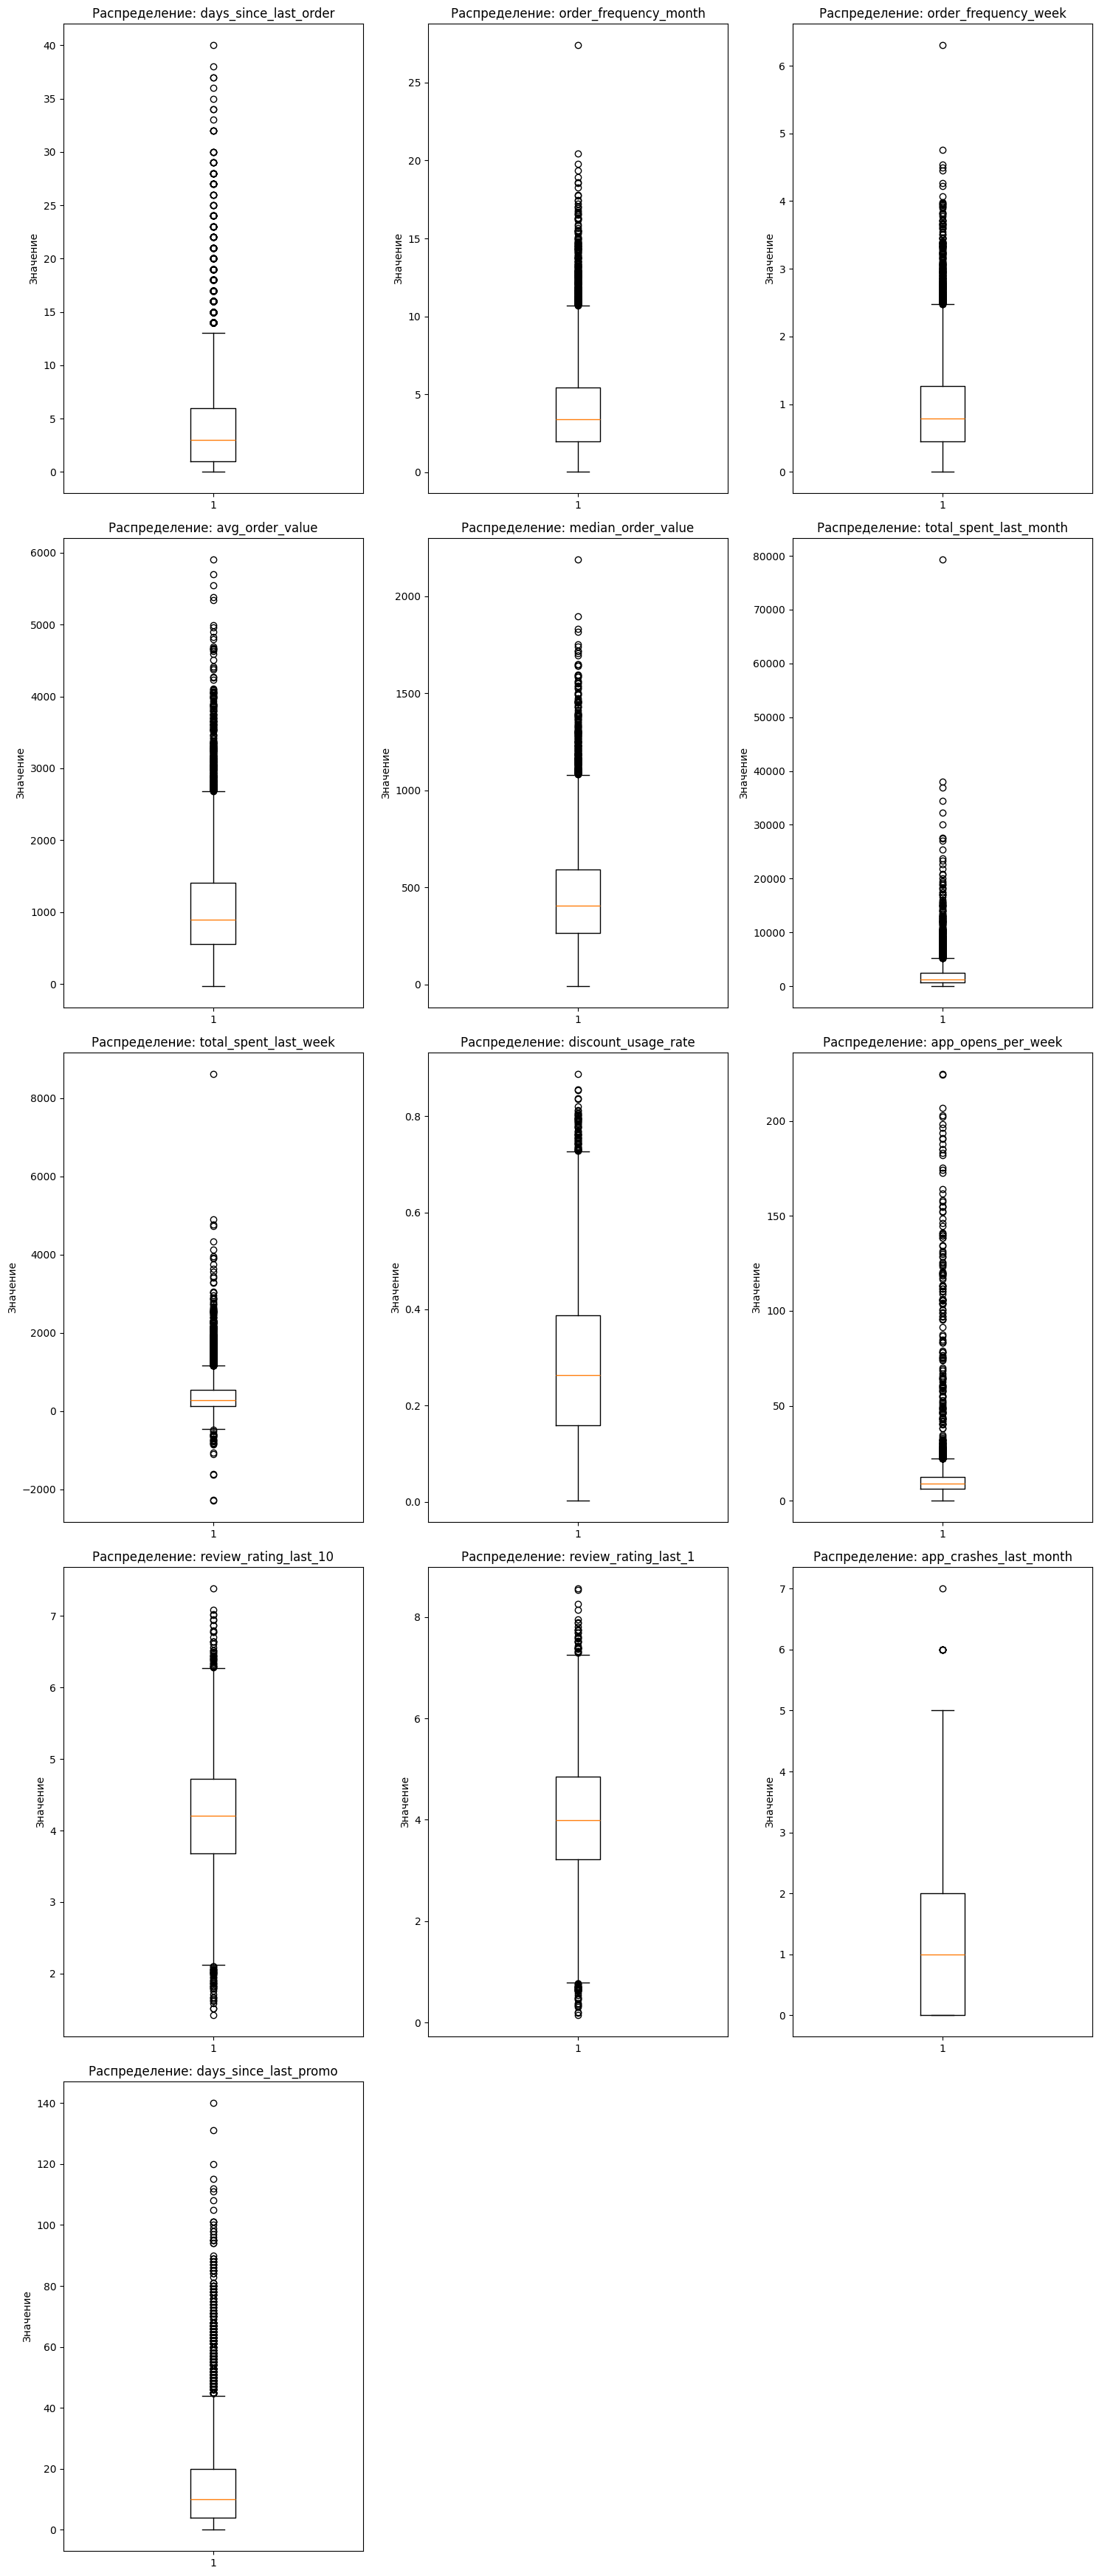

In [18]:
fig, axes = plt.subplots(nrows=5, ncols=3, figsize=(15, 35))

axes = axes.flatten()

numeric_columns = ['days_since_last_order',
                'order_frequency_month',
                'order_frequency_week',
                'avg_order_value',
                'median_order_value',
                'total_spent_last_month',
                'total_spent_last_week',
                'discount_usage_rate',
                'app_opens_per_week',
                'review_rating_last_10',
                'review_rating_last_1',
                'app_crashes_last_month',
                'days_since_last_promo']

for i, column in enumerate(numeric_columns):
    axes[i].boxplot(filtered_coffee_churn[column].dropna())
    axes[i].set_title(f'Распределение: {column}')
    axes[i].set_ylabel('Значение')

# Удаляем пустой график
fig.delaxes(axes[14])
fig.delaxes(axes[13])

plt.tight_layout()

plt.show()

В данных присутствуют некритичные выбросы: они отражают поведение пользователей, поэтому их удаление может стать причиной недообучения модели.

Дальше для улучшения метрик выбросы можно будет сгладить регуляризацией.

---

### 2.10. Анализ корреляции между признаками 

In [19]:
# Создание корреляционной матрицы
correlation_matrix = filtered_coffee_churn[
    filtered_coffee_churn.columns
].phik_matrix()

interval columns not set, guessing: ['days_since_last_order', 'order_frequency_month', 'order_frequency_week', 'avg_order_value', 'median_order_value', 'total_spent_last_month', 'total_spent_last_week', 'discount_usage_rate', 'seasonal_menu_tried', 'app_opens_per_week', 'notifications_enabled', 'review_rating_last_10', 'review_rating_last_1', 'app_crashes_last_month', 'days_since_last_promo', 'coffee_preference_change', 'churn']


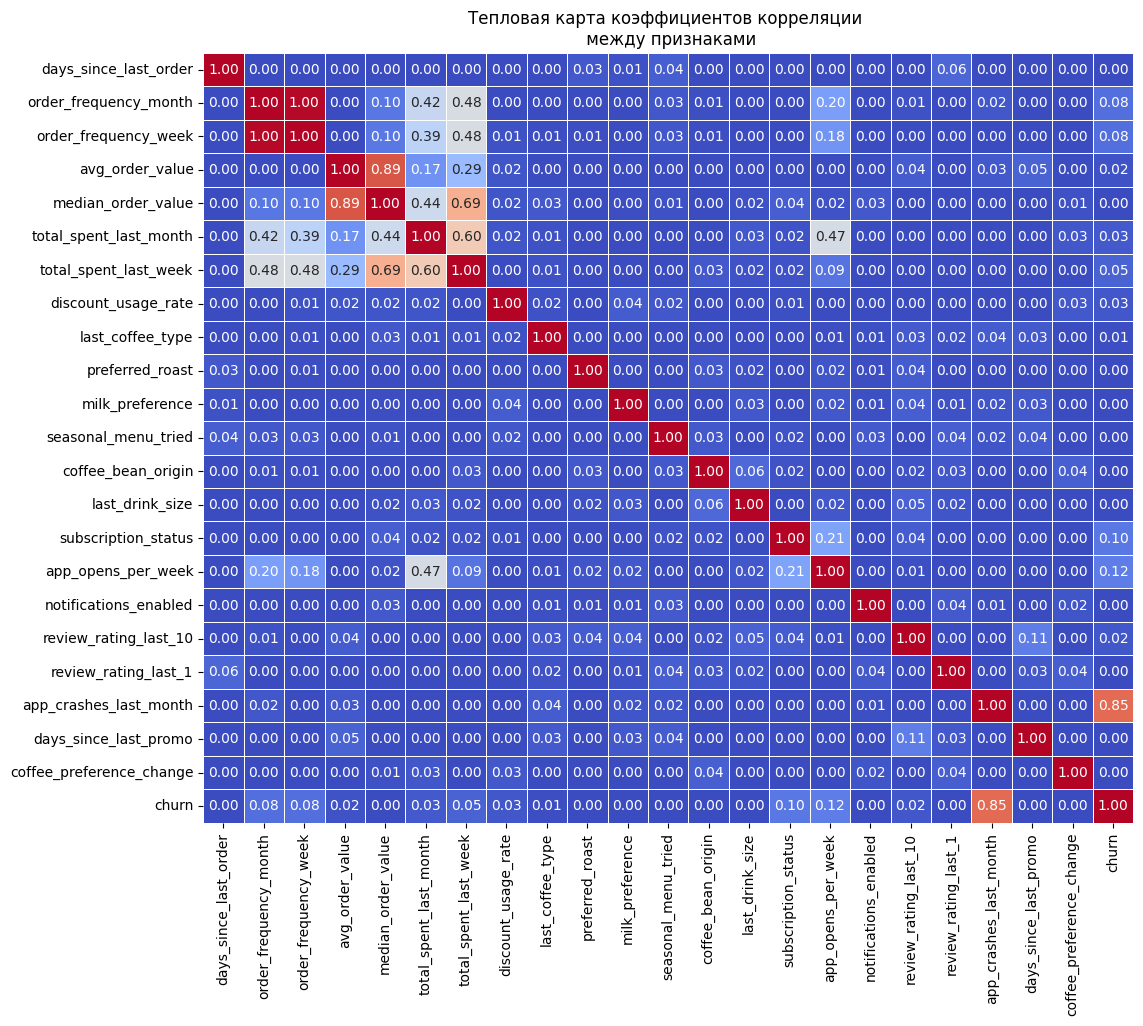

In [20]:
plt.figure(figsize=(12, 10))

sns.heatmap(
    data=correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5,
    cbar=False
)

plt.title('Тепловая карта коэффициентов корреляции \n между признаками')
plt.show()

`order_frequency_month` и `order_frequency_week` имеют абсолютную корреляцию между собой. Так как `order_frequency_month` содержит более полную информацию, этот признак оставлю, другой удалю.

`avg_order_value` и `median_order_value` сильно коррелируют между собой, что логично: их значения часто сходны. Однако, для обучения оставлю только `median_order_value`: он менее подвержен выбросам в данных в отличие от среднего значения. 

`total_spent_last_week` и `total_spent_last_month` так же имеют среднюю корреляцию из-за схожести хранимых значений. Оставлю только признак `total_spent_last_month`.

Целевая переменная `churn` не имеет даже слабовыраженной корреляции с данными за исключением признака `app_crashes_last_month`, который указывает на количество сбоев в приложении за последний момент. Можно предположить, что это главный фактор влияния на уход пользователей.



In [21]:
filtered_coffee_churn.drop(columns=['order_frequency_week', 'avg_order_value', 'total_spent_last_week'], inplace=True)

filtered_coffee_churn.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9957 entries, 0 to 10448
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   days_since_last_order     9062 non-null   float64
 1   order_frequency_month     9376 non-null   float64
 2   median_order_value        9162 non-null   float64
 3   total_spent_last_month    9670 non-null   float64
 4   discount_usage_rate       9575 non-null   float64
 5   last_coffee_type          9709 non-null   object 
 6   preferred_roast           9847 non-null   object 
 7   milk_preference           9322 non-null   object 
 8   seasonal_menu_tried       9015 non-null   float64
 9   coffee_bean_origin        9323 non-null   object 
 10  last_drink_size           9471 non-null   object 
 11  subscription_status       9077 non-null   object 
 12  app_opens_per_week        9107 non-null   float64
 13  notifications_enabled     9450 non-null   float64
 14  review_ratin

Изменения успешшно применены.

---


**Выводы по результатам исследовательского анализа данных** 

- Удалено 7 избыточных признаков.
- Удалено около 5% строк, содержащих предположительную техническую ошибку и дубликаты.
- Данные содержат большое количество шума в виде пропусков, которые никак не коррелируют между собой.
- В данных присутствуют некритичные выбросы, отражающие поведение пользователей.
- Скорее всего главный фактор ухода клиентов - признак `app_crashes_last_month`.

---

## 3. Предобработка данных

### 3.1. Разделение на выборки

Данные будут разделены на две выборки: обучающая (80%), тренировочная (20%). Обучать модель буду с помощью кросс-валидации.

In [22]:
X = filtered_coffee_churn.drop(columns='churn')
y = filtered_coffee_churn['churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, shuffle=True, random_state=RANDOM_STATE)

**Распределение данных по выборкам**

In [23]:
print('Процент значений churn = 1 в тренировочной выборке:', y_train.mean() * 100)
print('Процент значений churn = 1 в тестовой выборке:', y_test.mean() * 100)

Процент значений churn = 1 в тренировочной выборке: 6.001255492780917
Процент значений churn = 1 в тестовой выборке: 6.024096385542169


Целевая переменная распределилась равномерно.

### 3.2. Создание пайплайна

Пайплайн предобработки будет состоять из 3-х шагов:
1. Обработка пропусков
2. Кодировка категорий
3. Масштабирование

In [24]:
categorical = [
    'last_coffee_type',
    'preferred_roast',
    'milk_preference',
    'coffee_bean_origin',
    'last_drink_size',
    'subscription_status'
]

numeric = [
    'days_since_last_order',
    'order_frequency_month',
    'median_order_value',
    'total_spent_last_month',
    'discount_usage_rate',
    'seasonal_menu_tried',
    'app_opens_per_week',
    'notifications_enabled',
    'review_rating_last_10',
    'review_rating_last_1',
    'app_crashes_last_month',
    'days_since_last_promo',
    'coffee_preference_change'
]

to_onehot = [
    'last_coffee_type',
    'milk_preference',
    'coffee_bean_origin'
]

to_ordinal = [
    'preferred_roast',
    'last_drink_size',
    'subscription_status'
]

roast_order = [
    'unknown',
    'light',
    'medium',
    'dark'
]

drink_size_order = [
    'unknown',
    'small',
    'large',
    'medium'
]

sub_status_order = [
    'unknown',
    'none',
    'basic',
    'pro',
    'premium'
]

cat_ordinal_pipe = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='constant', fill_value='unknown')),
        ('ordinal encoding', OrdinalEncoder(categories=[roast_order, drink_size_order, sub_status_order]))
    ]
)

cat_onehot_pipe = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='constant', fill_value='unknown')),
        ('one-hot encoding', OneHotEncoder())
    ]
)

numeric_pipe = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ('categorical features to ordinal', cat_ordinal_pipe, to_ordinal),
        ('categorical features to one-hot', cat_onehot_pipe, to_onehot),
        ('numeric features', numeric_pipe, numeric)
    ]
)

Пайплайны успшено созданы.

---

## 4. Обучение модели

В качестве базовой модели используется DummyClassifier.

Для обучения моделей будет использоваться кросс-валидация.

In [25]:
# Для базовой модели используем prior, чтобы избежать уверенной ошибки от most_frequent
# и сформировать более адекватный порог качества моделей 
baseline_pipeline = Pipeline(
    steps=[
        ('preprocessing', preprocessor),
        ('classifier', DummyClassifier(strategy='prior', random_state=RANDOM_STATE))
    ]
)

logreg_pipeline = Pipeline(
    steps=[
        ('preprocessing', preprocessor),
        ('classifier', LogisticRegression(random_state=RANDOM_STATE))
    ]
)

В качестве основных метрик выберем:
- Логарифмическая функция потерь (`neg_log_loss`) - основная метрика для оценки качества обучения модели логистической регрессии.
- PR-AUC (`average_precision`) - основная метрика для оценки качества предсказаний для нашей конкретной задачи с несбалансированными данными. 

In [26]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

scoring = ['neg_log_loss', 'average_precision']

baseline_cv_results = cross_validate(estimator=baseline_pipeline, X=X_train, y=y_train, scoring=scoring, cv=cv)
logreg_cv_results = cross_validate(estimator=logreg_pipeline, X=X_train, y=y_train, scoring=scoring, cv=cv)

baseline_cv_means = {
    "log_loss": -baseline_cv_results['test_neg_log_loss'].mean(),
    "pr_auc": baseline_cv_results['test_average_precision'].mean()
}

logreg_cv_means = {
    "log_loss": -logreg_cv_results['test_neg_log_loss'].mean(),
    "pr_auc": logreg_cv_results['test_average_precision'].mean()
}

In [27]:
print('Результаты базовой модели:')
print('-' * 50)
print(f"Log loss: {baseline_cv_means['log_loss']:.3f}")
print(f"PR-AUC: {baseline_cv_means['pr_auc']:.3f}")
print('\n', '-' * 50, '\n')
print('Результаты логистической модели:')
print('-' * 50)
print(f"Log loss: {logreg_cv_means['log_loss']:.3f}")
print(f"PR-AUC: {logreg_cv_means['pr_auc']:.3f}")

Результаты базовой модели:
--------------------------------------------------
Log loss: 0.227
PR-AUC: 0.060

 -------------------------------------------------- 

Результаты логистической модели:
--------------------------------------------------
Log loss: 0.125
PR-AUC: 0.662


Между результатами базовой модели и результатами логистической модели с предобработкой данных большая пропасть.

Логистическая модель показывает практически идеальный результат:
- Значение `PR-AUC` 0.662 для несбалансированных данных с долей положительного класса около 6% указывает на способность найти значительную часть целевых объектов, не засыпая ложными срабатываниями. Результат в 10 раз больше случайного.
- Значене `Log loss` 0.125 показывает, что модель адекватно предсказывает вероятности: она снизила неопределенность в 2 раза по сравнению с базовой моделью.

Далее проверим, возможно ли улучшить результаты логистической модели с помощью подбора гиперпараметров и добавления новых признаков.

---


## 5. Создание новых признаков

### 5.1. Создание новых признаков

**Производные признаки**

- `data_completeness` на основе всех данных: наличие заполнение остальных признаков, отражающее разборчивость пользователя в сервисе;
- `discount_usage_rate` * `days_since_last_promo`: индекс лояльности к скидкам;
- `review_rating_last_1` - `review_rating_last_10`: отрицательное значение - недовольство последним опытом;
- `app_crashes_last_month` / `app_opens_per_week`: плотность вылетов приложения на посещение. Пользователь не будет пользоваться плохо работающим приложением и удалит его;

**Логарифмирование**

Признаки, наиболее подверженные содержанию "тяжелых хвостов"  - `median_order_value` и `total_spent_last_month`, имеют отрицательные значения, которые могут указывать на возврат. Это не позволит использовать логарифмирование для столбца.

Поэтому добавим бинарный признак `is_return`, который будет указывать на наличие возврата и определяться по отрицательным значениям столбцов. Сами отрицательные значения заменим на ноль. 

Хотя в данных всего 2 пользователя с отрицательными значениями в этих признаках, ничего не гарантирует, что в будущем не появится больше отрицательных значений. 

**Бинаризация**

- `is_paying_customer` на основе `subscription_status`: платящий пользователь с наименьшей вероятснотью скоро уйдет;
- `is_alternative_milk` на основе `milk_preference`: пользователь, разобравшийся в предпочтениях более осознанно подходит к покупке;

In [28]:
# Создаем фукнцию для будущего трансформера признаков
def create_new_features(X):
    # Работаем с копией, чтобы не портить исходные данные
    X = X.copy()
    
    # Подготовка к логарифмированию
    X['is_return'] = ((X['median_order_value'] < 0) | (X['total_spent_last_month'] < 0)).astype(int)

    X['median_order_value'] = X['median_order_value'].clip(lower=0)
    X['total_spent_last_month'] = X['total_spent_last_month'].clip(lower=0)
    
    # Производные признаки
    X['data_completeness'] = X.isna().sum(axis=1)
    X['discounts_loyalty'] = X['discount_usage_rate'] * X['days_since_last_promo']
    X['rating_shake'] = X['review_rating_last_1'] - X['review_rating_last_10']
    X['crashes_density'] = X['app_crashes_last_month'] / (X['app_opens_per_week'] + 1e-9)
    
    # Логарифмирование
    X['log_median_order_value'] = np.log1p(X['median_order_value'])
    X['log_total_spent_last_month'] = np.log1p(X['total_spent_last_month'])
    
    # Бинаризация
    X['is_paying_customer'] = X['subscription_status'].isin(['basic', 'premium', 'pro']).astype(int)
    X['is_alternative_milk'] = X['milk_preference'].isin(['almond', 'oat', 'soy']).astype(int)
    
    return X

In [29]:
# Трансформер изменения и добавления признаков
feature_engineering_transformer = FunctionTransformer(create_new_features, check_inverse=False)

---

### 5.2. Обновление пайплайна и результаты с новыми признаками


In [30]:
X = filtered_coffee_churn.drop(columns='churn')
y = filtered_coffee_churn['churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, shuffle=True, random_state=RANDOM_STATE)

In [31]:
numeric.extend(['data_completeness', 'discounts_loyalty', 'rating_shake', 'crashes_density', 'is_paying_customer', 'is_alternative_milk', 'is_return'])

preprocessor = ColumnTransformer(
    transformers=[
        ('categorical features to ordinal', cat_ordinal_pipe, to_ordinal),
        ('categorical features to one-hot', cat_onehot_pipe, to_onehot),
        ('numeric features', numeric_pipe, numeric)
    ]
)

In [32]:
logreg_pipeline = Pipeline(
    steps=[
        ('feature_eng', feature_engineering_transformer),
        ('preprocessing', preprocessor),
        ('classifier', LogisticRegression(random_state=RANDOM_STATE))
    ]
)

In [33]:
logreg_cv_results = cross_validate(estimator=logreg_pipeline, X=X_train, y=y_train, scoring=scoring, cv=cv, return_estimator=True)

logreg_cv_means_new = {
    "log_loss": -logreg_cv_results['test_neg_log_loss'].mean(),
    "pr_auc": logreg_cv_results['test_average_precision'].mean()
}

In [34]:
print('Результаты логистической модели с новыми признаками:')
print('-' * 50)
print(f"Log loss: {logreg_cv_means_new['log_loss']:.3f}")
print(f"PR-AUC: {logreg_cv_means_new['pr_auc']:.3f}")
print()
print('Разница результатов моделей с новыми признаками и без них')
print('-' * 50)
print(f"Log loss diff: {(logreg_cv_means_new['log_loss'] - logreg_cv_means['log_loss']):.3f}")
print(f"PR-AUC: {(logreg_cv_means_new['pr_auc'] - logreg_cv_means['pr_auc']):.3f}")

Результаты логистической модели с новыми признаками:
--------------------------------------------------
Log loss: 0.124
PR-AUC: 0.661

Разница результатов моделей с новыми признаками и без них
--------------------------------------------------
Log loss diff: -0.001
PR-AUC: -0.001


Метрики показали незначительные улучшения. 

Это связано с тем, что наиболее коррелирующим признаком ухода клиентов является `app_crashes_last_month`. Однако, было принято решение не делать возведение в квадрат этого признака для усиления влияния, потому что зависимость и без того явная, а новый признак лишь добавил бы шума данным. 

---

### 5.3. Отбор признаков

Для отбора признаков обучим модель логистической регрессии с регуляризацией `l1`, которая агрессивно зануляет маловажные признаки. 

In [35]:
logreg_l1_pipeline = Pipeline(
    steps=[
        ('feature_eng', feature_engineering_transformer),
        ('preprocessing', preprocessor),
        # Пришлось заменить solver, т.к. исходный не умеет работать с l1
        ('classifier', LogisticRegression(penalty='l1', solver='liblinear', random_state=RANDOM_STATE))
    ]
)

In [36]:
logreg_l1_cv_results = cross_validate(estimator=logreg_l1_pipeline, X=X_train, y=y_train, scoring=scoring, cv=cv, return_estimator=True)

logreg_l1_cv_means = {
    "log_loss": -logreg_l1_cv_results['test_neg_log_loss'].mean(),
    "pr_auc": logreg_l1_cv_results['test_average_precision'].mean()
}

In [37]:
print('Результаты логистической модели с регуляризацией Lasso:')
print('-' * 50)
print(f"Log loss: {logreg_cv_means['log_loss']:.3f}")
print(f"PR-AUC: {logreg_cv_means['pr_auc']:.3f}")

Результаты логистической модели с регуляризацией Lasso:
--------------------------------------------------
Log loss: 0.125
PR-AUC: 0.662


In [38]:
# Получаем названия признаков последнего пайплайна
feature_names = logreg_l1_cv_results['estimator'][-1].named_steps['preprocessing'].get_feature_names_out()

# Получаем итоговые коэффициенты
coefficients = logreg_l1_cv_results['estimator'][-1].named_steps['classifier'].coef_[0]

# Создаем таблицу для удобства интерпритации
coef_df = pd.DataFrame({'feature': feature_names, 'coef': coefficients})

print(coef_df.sort_values(by='coef', ascending=False))


                                              feature      coef
31           numeric features__app_crashes_last_month  2.102102
22            numeric features__order_frequency_month  0.610559
27               numeric features__app_opens_per_week  0.272922
34                numeric features__data_completeness  0.250473
5   categorical features to one-hot__last_coffee_t...  0.219101
2   categorical features to ordinal__subscription_...  0.204696
32            numeric features__days_since_last_promo  0.184763
14  categorical features to one-hot__coffee_bean_o...  0.182371
13  categorical features to one-hot__milk_preferen...  0.128455
0    categorical features to ordinal__preferred_roast  0.081071
33         numeric features__coffee_preference_change  0.080744
16  categorical features to one-hot__coffee_bean_o...  0.072759
30             numeric features__review_rating_last_1  0.065638
23               numeric features__median_order_value  0.064333
9   categorical features to one-hot__mil

Как и показала ранее корреляционная матрица, самым важным признаком оказался `app_crashes_last_month`. Следующий значимый по важности признак `order_frequence_month`.

Менее значимыми признаками оказались категории `milk_preference` и `coffee_bean_origin`. 

Удалим их из датафрейма и признаков к категоризации.

In [39]:
to_onehot.remove('milk_preference')
to_onehot.remove('coffee_bean_origin')

to_onehot

['last_coffee_type']

---

## 6. Эксперименты с гиперпараметрами

Для модели логистической регрессии будем регулировать гиперпараметры:
- Регуляризация: `l1`, `l2`;
- Сила регуляризации: 0.001, 0.01, 0.1, 1, 10;
- Количество фолдов для обучения кросс-валидацией.

In [40]:
X = filtered_coffee_churn.drop(columns='churn')
y = filtered_coffee_churn['churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, shuffle=True, random_state=RANDOM_STATE)

In [41]:
final_preprocessor = ColumnTransformer(
    transformers=[
        ('categorical features to ordinal', cat_ordinal_pipe, to_ordinal),
        ('categorical features to one-hot', cat_onehot_pipe, to_onehot),
        ('numeric features', numeric_pipe, numeric)
    ]
)

In [42]:
logreg_pipeline = Pipeline(steps=[
    ('feature_eng', feature_engineering_transformer),
    ('preprocessing', final_preprocessor),
    ('classifier', LogisticRegression(random_state=RANDOM_STATE))
])

# Используем список словарей, чтобы связать l1 с liblinear
param_grid = [
    {
        'classifier__penalty': ['l1'],
        'classifier__solver': ['liblinear'],
        'classifier__C': [0.001, 0.01, 0.1, 1, 10, 100]
    },
    {
        'classifier__penalty': ['l2'],
        'classifier__solver': ['lbfgs'],
        'classifier__C': [0.001, 0.01, 0.1, 1, 10, 100]
    }
]

all_results = []

for n in [5, 7, 10, 15]:
    cv = StratifiedKFold(n_splits=n, shuffle=True, random_state=RANDOM_STATE)
    
    grid_search = GridSearchCV(
        estimator=logreg_pipeline,
        param_grid=param_grid,
        scoring=['neg_log_loss', 'average_precision'],
        refit='average_precision', # указываем основную метрику для выбора лучшей модели
        cv=cv,
        n_jobs=-1 # задействуем все ядра процессора
    )
    
    grid_search.fit(X_train, y_train)
    
    res_df = pd.DataFrame(grid_search.cv_results_)
    res_df['n_splits'] = n
    all_results.append(res_df)

final_results = pd.concat(all_results, ignore_index=True)

report = final_results[[
    'mean_test_average_precision', 
    'mean_test_neg_log_loss', 
    'n_splits', 
    'param_classifier__penalty', 
    'param_classifier__C'
]].copy()

report.columns = ['pr_auc', 'log_loss', 'n_splits', 'penalty', 'alpha']
report['log_loss'] = -report['log_loss']

display(report.sort_values(by='pr_auc', ascending=False).head(10))

,pr_auc,log_loss,n_splits,penalty,alpha
2,0.672801,0.123727,5,l1,0.10
7,0.671926,0.129952,5,l2,0.01
8,0.671601,0.123356,5,l2,0.10
3,0.671146,0.123314,5,l1,1.00
14,0.670202,0.123993,7,l1,0.10
20,0.669768,0.123441,7,l2,0.10
15,0.669630,0.123453,7,l1,1.00
21,0.669153,0.123551,7,l2,1.00
9,0.668974,0.123532,5,l2,1.00
4,0.668938,0.123556,5,l1,10.00


По итогам подбора гиперпараметров лучшими параметрами стали: `n_splits`=5, `penalty`=l1, `alpha`=0.1.

Модель логистической регрессии с такими параметрами показала `pr_auc` = 0.673 и `log_logg` = 0.124.

---

## 7. Подготовка финальной модели

In [43]:
X = filtered_coffee_churn.drop(columns='churn')
y = filtered_coffee_churn['churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=RANDOM_STATE)

In [44]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

final_pipeline = Pipeline(
    steps=[
        ('feature_eng', feature_engineering_transformer),
        ('preprocessing', final_preprocessor),
        ('classifier', LogisticRegression(penalty='l1', solver='liblinear', C=0.1, random_state=RANDOM_STATE))
    ]
)

final_pipeline.fit(X_train, y_train)

y_pred_proba = final_pipeline.predict_proba(X_test)[:, 1]

print(f"Log Loss на тесте: {log_loss(y_test, y_pred_proba):.3f}")
print(f"PR-AUC на тесте: {average_precision_score(y_test, y_pred_proba):.3f}")

Log Loss на тесте: 0.114
PR-AUC на тесте: 0.714


In [45]:
feature_names = final_pipeline.named_steps['preprocessing'].get_feature_names_out()

coefficients = final_pipeline.named_steps['classifier'].coef_[0]

coef_df = pd.DataFrame({'feature': feature_names, 'coef': coefficients})

print(coef_df.sort_values(by='coef', ascending=False).head())

                                              feature      coef
17           numeric features__app_crashes_last_month  1.907425
8             numeric features__order_frequency_month  0.451995
13               numeric features__app_opens_per_week  0.175885
20                numeric features__data_completeness  0.118389
2   categorical features to ordinal__subscription_...  0.078605


---

## 8. Отчет о проделанной работе

Финальная модель показала отличный результат:
- Значение `PR-AUC` 0.683 для несбалансированных данных с долей положительного класса около 6% указывает на способность модель найти значительную часть целевых объектов, не засыпая систему ложными срабатываниями.
- Значение `Log Loss` 0.123 показывает, что модель адекватно предсказывает вероятности: например, не делает уверенных ошибок.

Факторы, больше остальных влияющие на предсказания:
- Однозначно, главный фактор - количество сбоев в приложении за последний месяц. Большие значения в `app_crashes_last_month` негативно влияют на пользовательский опыт и создают отток клиентов. Рекомендуется обнаружить и минимизировать проблемы с приложением для уменьшения оттока пользователей.
- Менее значимые факторы, влияющие на отток пользователей: `order_frequency_month` или частота заказов за месяц и `app_opens_per_week` или количество открытия приложения за неделю. Второй фактор может раскрывать проблему: чем больше пользователь открывает приложение, тем более вероятно, что он столкнется с сбоем.

---

## 9. Сохранение модели для продакшена

Для сохранения итогового пайплайна и модели будет использована библиотека `joblib`.

In [46]:
model_name = f"churn_detection.joblib"

metadata = {
    'model_version': 1.0,
    'training_date': '2026-03-13',
    'PR-AUC': 0.683,
    'features': numeric + to_onehot + to_ordinal
}

joblib.dump({
    'model': final_pipeline,
    'metadata': metadata
}, model_name)

['churn_detection.joblib']

Проверка: 

In [47]:
loaded_model = joblib.load('churn_detection.joblib')

prediction = loaded_model['model'].predict(X_test)

prediction

array([0, 0, 0, ..., 0, 0, 0])

Модель успешно сохранения и работает после загрузки и запуска.

---